# Home Credit: run the experiments

We compare logistic regression and LightGBM. We also test whether new features and past loan records help, and what happens when we remove the external scores.

This notebook starts with a small sample to check the code. The full-data results are in `home_credit_results.ipynb`. The default settings here will give different results.


## 1. Set the paths and options

Run this notebook from the project folder or its `notebooks` folder. Use a Python environment with the packages listed in `requirements.txt`. Put the CSV files in `data/raw`.

The quick run uses 30,000 applications, 3 folds and 150 trees. To use the full-data settings, change `MAX_ROWS` to `None`, `FOLDS` to `5`, `TREES` to `400`, and `WITH_BUREAU` to `True`. Set `MAKE_SUBMISSION=True` if you need predictions for Kaggle.

Use a new output folder for each run. `SEED` sets the random split, and `THREADS` sets the number of CPU threads.


In [ ]:
%matplotlib inline
from pathlib import Path
import json
import sys

import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import display
from sklearn.metrics import roc_curve, precision_recall_curve
from sklearn.metrics import roc_auc_score, average_precision_score, brier_score_loss
from sklearn.calibration import calibration_curve

# Locate the project whether Jupyter starts in the root or notebooks directory.
ROOT = Path.cwd()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent
if not (ROOT / "src" / "train.py").is_file():
    raise FileNotFoundError("Run from the miniproject folder or its notebooks folder.")
sys.path.insert(0, str(ROOT))
from src.train import load_applications, run_experiments

DATA_DIR = ROOT / "data" / "raw"
from datetime import datetime
OUTPUT_DIR = ROOT / "outputs" / ("notebook_quick_" + datetime.now().strftime("%Y%m%d_%H%M%S_%f"))
# Quick-run settings; see the text above for the full-data configuration.
MAX_ROWS = 30000
FOLDS = 3
TREES = 150
THREADS = 4
SEED = 42
WITH_BUREAU = False
MAKE_SUBMISSION = False

plt.rcParams.update({"font.size": 11, "axes.spines.top": False, "axes.spines.right": False, "axes.grid": False})


## 2. Read the data

`load_applications` reads both application files and checks the IDs, labels and columns. `TARGET` is the answer: 1 means payment difficulties under the data definition. `SK_ID_CURR` is an application ID. Neither column is used as an input feature.

The table below uses all rows in the files. The training function takes the small sample later. The test file has no labels, so its positive rate is unknown.


In [ ]:
train, test = load_applications(DATA_DIR)
counts = train["TARGET"].value_counts().sort_index()
profile = pd.DataFrame({
    "rows": [len(train), len(test)],
    "predictor_columns": [train.shape[1] - 2, test.shape[1] - 1],
    "default_fraction": [train["TARGET"].mean(), float("nan")],
}, index=["application_train", "application_test"])
display(profile)
print("Training label counts:", counts.to_dict())


,rows,predictor_columns,default_fraction
application_train,307511,120,0.080729
application_test,48744,120,NaN


Training label counts: {0: 282686, 1: 24825}


## 3. Look at the labels and missing values

First, count the two classes. Then plot the 12 columns with the most missing values. These plots use the full training file.

We do not fill missing values here. That happens inside each training fold, using only that fold's training rows.


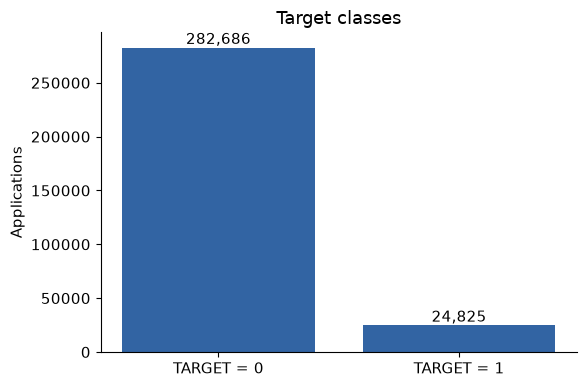

In [ ]:
fig, ax = plt.subplots(figsize=(6, 4))
counts.index = counts.index.map({0: "TARGET = 0", 1: "TARGET = 1"})
ax.bar(counts.index, counts.values, color="#3264A3")
ax.set(ylabel="Applications", title="Target classes")
ax.set_ylim(bottom=0)
for i, value in enumerate(counts):
    ax.text(i, value, f"{value:,}", ha="center", va="bottom")
ax.margins(y=0.15)
fig.tight_layout()
plt.show()


,missing_fraction
COMMONAREA_MODE,0.698723
COMMONAREA_MEDI,0.698723
COMMONAREA_AVG,0.698723
NONLIVINGAPARTMENTS_MEDI,0.694330
NONLIVINGAPARTMENTS_AVG,0.694330
NONLIVINGAPARTMENTS_MODE,0.694330
FONDKAPREMONT_MODE,0.683862
LIVINGAPARTMENTS_AVG,0.683550
LIVINGAPARTMENTS_MODE,0.683550
LIVINGAPARTMENTS_MEDI,0.683550


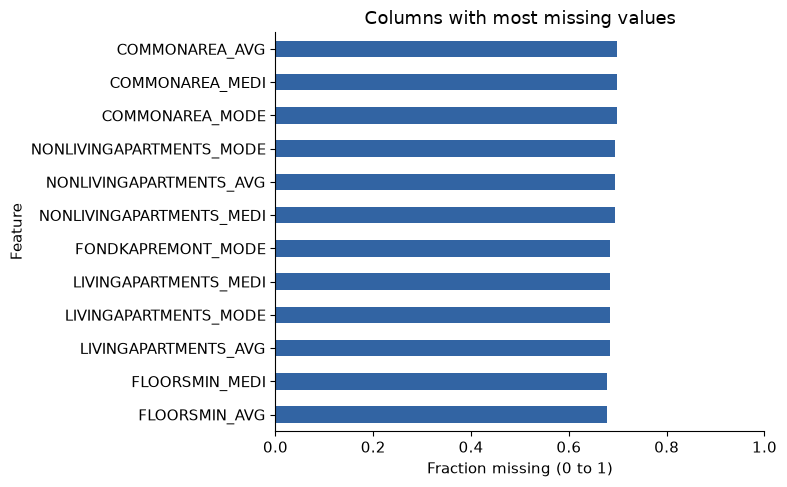

In [ ]:
# isna() returns booleans; their column means give the missing fractions.
features = train.drop(columns=["SK_ID_CURR", "TARGET"])
missingness = features.isna().mean()
missingness = missingness.sort_values(ascending=False)
top_missing = missingness.head(12)
display(top_missing.rename("missing_fraction").to_frame())

fig, ax = plt.subplots(figsize=(8, 5))
top_missing.sort_values().plot.barh(ax=ax, color="#3264A3")
ax.set(xlim=(0, 1), xlabel="Fraction missing (0 to 1)", ylabel="Feature", title="Columns with most missing values")
fig.tight_layout()
plt.show()


## 4. Train the models

The next cell calls `run_experiments` in `src/train.py`. It does the following:

1. Takes a sample if `MAX_ROWS` is set.
2. Keeps 20% of the labelled rows as a final holdout set.
3. Uses the other 80% to compare models with cross-validation.
4. Chooses the setup with the highest mean AUC.
5. Fits that setup on the whole development set and scores the holdout.

All models use the same folds. Missing-value filling and encoding are fitted on each training fold. Logistic regression also scales the numeric columns.

| Setup | Model and inputs |
|---|---|
| `dummy_prior` | Predict the training positive rate for every row |
| `logistic_raw` | Logistic regression with the cleaned original columns |
| `logistic_engineered` | Logistic regression with added features |
| `lightgbm_raw` | LightGBM with the cleaned original columns |
| `lightgbm_engineered` | LightGBM with added features |
| `lightgbm_no_external` | LightGBM without external scores and their summaries |
| `lightgbm_with_bureau` | LightGBM with past loan summaries; needs `WITH_BUREAU=True` |

The added features include five ratios, age, and score summaries. Past loans are grouped by application ID before joining, so each application still has one row.

These are the main training steps inside the function. This example is not run again here:

```python
pipeline.fit(features.iloc[fit_indices], y[fit_indices])
p = pipeline.predict_proba(features.iloc[valid_indices])[:, 1]
scores = metric_values(y[valid_indices], p)
```

The pipeline includes data processing and the model. `[:, 1]` selects the probability of class 1. Keeping the function in one file avoids having two different training routines. The function saves the scores and predictions. The cells below use those files to draw the plots.


In [ ]:
summary = run_experiments(
    data_dir=DATA_DIR, output_dir=OUTPUT_DIR,
    folds=FOLDS, seed=SEED, max_rows=MAX_ROWS,
    with_bureau=WITH_BUREAU, make_submission=MAKE_SUBMISSION,
    threads=THREADS, trees=TREES,
)
display(summary.round(5))


dummy_prior: fold 1/3, AUC=0.50000


dummy_prior: fold 2/3, AUC=0.50000


dummy_prior: fold 3/3, AUC=0.50000


logistic_raw: fold 1/3, AUC=0.72525


logistic_raw: fold 2/3, AUC=0.75110


...

lightgbm_no_external: fold 1/3, AUC=0.67496


lightgbm_no_external: fold 2/3, AUC=0.68971


lightgbm_no_external: fold 3/3, AUC=0.68241


Selected: lightgbm_engineered; final holdout AUC=0.72080


,experiment,n_features,cv_auc_mean,cv_auc_std,oof_auc,oof_average_precision,oof_brier_score,seconds
0,lightgbm_engineered,130,0.74810,0.01374,0.74785,0.22861,0.06851,3.94062
1,lightgbm_raw,121,0.74729,0.01208,0.74699,0.22479,0.06872,3.77818
2,logistic_engineered,130,0.73840,0.01290,0.73824,0.21042,0.06964,3.06757
3,logistic_raw,121,0.73691,0.01311,0.73676,0.21013,0.06963,2.57371
4,lightgbm_no_external,124,0.68236,0.00737,0.68231,0.16350,0.07175,3.74155
5,dummy_prior,121,0.50000,0.00000,0.50000,0.08075,0.07423,0.61604


## 5. Compare the models

Each dot shows mean AUC. Its bar shows one fold standard deviation. We also subtract the scores of two setups within each fold. A positive difference means the first setup did better.

The bureau comparison is skipped if it was not run. Checking all fold differences is more useful than looking only at the best average score.


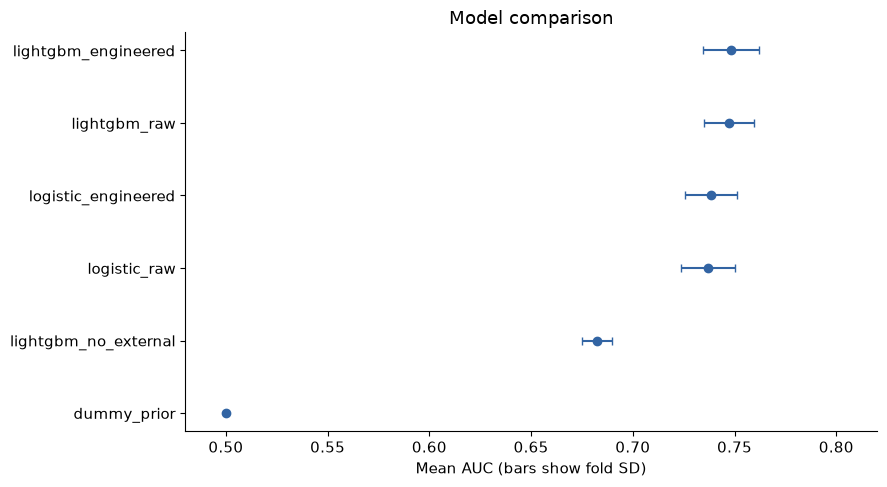

,tree_vs_linear_raw,linear_feature_gain,tree_feature_gain,external_score_gain
fold,,,,
1,0.00996,0.00213,-0.00015,0.06010
2,0.00828,0.00149,0.00307,0.07275
3,0.01289,0.00086,-0.00049,0.06436


In [ ]:
ordered = summary.sort_values("cv_auc_mean")
positions = range(len(ordered))
fig, ax = plt.subplots(figsize=(9, 5))
ax.errorbar(ordered["cv_auc_mean"], positions,
            xerr=ordered["cv_auc_std"], fmt="o", color="#3264A3", capsize=3)
ax.set_yticks(positions, ordered["experiment"])
ax.set_xlim(0.48, 0.82)
ax.set_xlabel("Mean AUC (bars show fold SD)")
ax.set_title("Model comparison")
fig.tight_layout()
fig.savefig(OUTPUT_DIR / "cv_comparison.png", dpi=160)
plt.show()

fold_scores = pd.read_csv(OUTPUT_DIR / "cv_folds.csv")
paired = fold_scores.pivot(index="fold", columns="experiment", values="roc_auc")

comparisons = {
    "tree_vs_linear_raw": ("lightgbm_raw", "logistic_raw"),
    "linear_feature_gain": ("logistic_engineered", "logistic_raw"),
    "tree_feature_gain": ("lightgbm_engineered", "lightgbm_raw"),
    "external_score_gain": ("lightgbm_engineered", "lightgbm_no_external"),
    "bureau_gain": ("lightgbm_with_bureau", "lightgbm_engineered"),
}

differences = {}
for label, (model_a, model_b) in comparisons.items():
    # The bureau comparison is available only when that configuration was run.
    if model_a in paired.columns and model_b in paired.columns:
        differences[label] = paired[model_a] - paired[model_b]

deltas = pd.DataFrame(differences)
display(deltas.round(5))


## 6. Check the holdout scores

The JSON file stores scores from the training run. We read it as a Python dictionary. Then we read the saved predictions, check AUC, AP and Brier again, and draw ROC and precision-recall curves.

The calibration plot compares predicted risk with the actual positive rate in ten groups. Points close to the grey line show better agreement. AP is average precision, not the area found by joining PR points with straight lines.


selected_experiment                                                         lightgbm_engineered
n                                                                                          6000
default_fraction                                                                       0.080667
roc_auc                                                                                0.720803
average_precision                                                                      0.210453
brier_score                                                                            0.069609
auc_fixed_prediction_bootstrap_95_interval             [0.6953083048412132, 0.7446762124008893]
interval_note                                 Stratified application bootstrap, 1000 draws; ...
Name: final_holdout, dtype: object

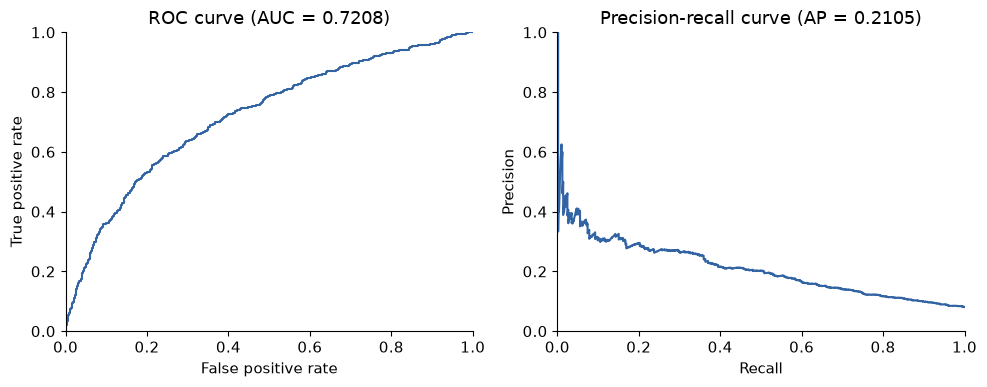

In [ ]:
metrics_file = OUTPUT_DIR / "holdout_metrics.json"
holdout = json.loads(metrics_file.read_text())
display(pd.Series(holdout, name="final_holdout"))
predictions = pd.read_csv(OUTPUT_DIR / "holdout_predictions.csv")
y_true = predictions["TARGET"]
y_prob = predictions["probability"]
fpr, tpr, thresholds = roc_curve(y_true, y_prob)
precision, recall, thresholds = precision_recall_curve(y_true, y_prob)

# Calculate the scores from the saved predictions, then check the saved metrics.
auc = roc_auc_score(y_true, y_prob)
ap = average_precision_score(y_true, y_prob)
brier = brier_score_loss(y_true, y_prob)
assert abs(auc - holdout["roc_auc"]) < 1e-10
assert abs(ap - holdout["average_precision"]) < 1e-10
assert abs(brier - holdout["brier_score"]) < 1e-10

fig, axes = plt.subplots(1, 2, figsize=(10, 4))
axes[0].plot(fpr, tpr, color="#3264A3")
axes[0].set_xlabel("False positive rate")
axes[0].set_ylabel("True positive rate")
axes[0].set_title(f"ROC curve (AUC = {auc:.4f})")
axes[1].plot(recall, precision, color="#3264A3")
axes[1].set_xlabel("Recall")
axes[1].set_ylabel("Precision")
axes[1].set_title(f"Precision-recall curve (AP = {ap:.4f})")
for ax in axes:
    ax.set_xlim(0, 1)
    ax.set_ylim(0, 1)
fig.tight_layout()
fig.savefig(OUTPUT_DIR / "holdout_curves.png", dpi=160)
plt.show()


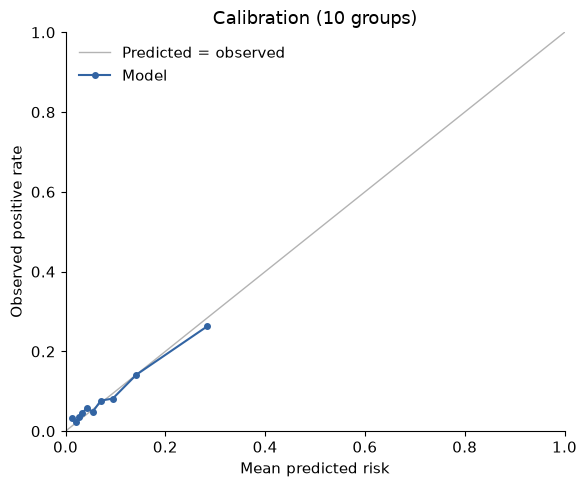

Stratified application bootstrap, 1000 draws; conditional on this fitted model. Does not include training/model-selection uncertainty.


In [ ]:
# Use the same ten equal-size groups as the original plot.
observed, predicted = calibration_curve(y_true, y_prob, n_bins=10, strategy="quantile")
fig, ax = plt.subplots(figsize=(6, 5))
ax.plot([0, 1], [0, 1], color="0.7", linewidth=1, label="Predicted = observed")
ax.plot(predicted, observed, "o-", color="#3264A3", markersize=4, label="Model")
ax.set_xlim(0, 1)
ax.set_ylim(0, 1)
ax.set_xlabel("Mean predicted risk")
ax.set_ylabel("Observed positive rate")
ax.set_title("Calibration (10 groups)")
ax.legend(frameon=False)
fig.tight_layout()
fig.savefig(OUTPUT_DIR / "holdout_calibration.png", dpi=160)
plt.show()
print(holdout["interval_note"])


## 7. Check the saved files

OOF means out-of-fold: each prediction comes from a model that did not train on that row. Check that all predictions exist and lie between 0 and 1. Also check that IDs are unique and the holdout row count matches the score file.

Finally, print the sample size and chosen setup. These checks can find basic mistakes, but they do not prove that every part of the study is correct.


In [ ]:
oof = pd.read_csv(OUTPUT_DIR / "development_oof.csv")
# Exclude identifiers and labels before checking the prediction columns.
probabilities = oof.drop(columns=["SK_ID_CURR", "TARGET"])
assert probabilities.notna().all().all()
assert ((probabilities >= 0) & (probabilities <= 1)).all().all()
assignments = pd.read_csv(OUTPUT_DIR / "split_assignments.csv")
assert assignments["SK_ID_CURR"].is_unique
assert int(assignments["split"].eq("holdout").sum()) == holdout["n"]
metadata = json.loads((OUTPUT_DIR / "run_metadata.json").read_text())
print("Checks passed. Labelled rows used:", metadata["used_train_rows"])
print("Sampled run:", metadata["sampled_run"])
print("Selected setup:", holdout["selected_experiment"])


Checks passed. Labelled rows used: 30000
Sampled run: True
Selected setup: lightgbm_engineered


## Write up the run

Record the sample size, settings and output folder. Use the full-data run for the main report, rather than the quick run.

Fold standard deviation is not a confidence interval. The bootstrap interval uses a fixed model and does not cover changes from training or model choice. Feature importance is not a cause-and-effect result. A random split also does not test future loan data.

State each member's work and how AI tools were used.
